# Project 2 – Neural network: latent space with t-SNE and UMAP
Based on the Week 9 exercise (*LatentVisualization*), but with our own diabetes neural network instead of the MNIST CNN.

In Week 9 we visualized the representation after each conv layer. Here we do the same for each layer of our MLP:

| Week 9 (MNIST CNN) | This notebook (diabetes NN) |
|---|---|
| c1, c2, c3, c4 feature maps | input (21), hidden layer 1 (32), hidden layer 2 (16) |
| coloured by digit 0–9 | coloured by `Diabetes_012` (0 / 1 / 2) |
| Exercise 1: t-SNE vs PCA | Section 4 |
| Exercise 3: perplexity | Section 5 |
| Exercise 4: UMAP | Section 6 |

Exercise 2 (rotational augmentation) is image-specific and has no meaningful counterpart for tabular data, so it is left out.

We do **not** train a new model: the trained model and data split are loaded by running `Project2_NN_clean.ipynb` (Section 2).

## 1. Setup

In [1]:
%pip install umap-learn scikit-learn pandas numpy matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.


## 2. Load our trained model from `Project2_NN_clean.ipynb`
Instead of training a new model, we run the main notebook in this kernel with `%run`.
That gives us **the same trained `model`**, the same data split (`X_test`, `X_test_raw`, `y_test`, `y012_test`, ...) and the same `FEATURE_COLS`.

The whole main notebook is executed (training, LIME, SHAP, ...), so this cell takes a few minutes.
Its output is hidden with `%%capture`. Run `main_log.show()` in a new cell to see it.

In [2]:
%%capture main_log
%run Project2_NN_clean.ipynb

In [3]:
plt.close('all')   # figures from the main notebook are not needed here

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

warnings.filterwarnings('ignore', message='n_jobs value')   # UMAP warns when random_state is set
warnings.filterwarnings('ignore', message='compatibility_layout', category=FutureWarning)   # UMAP 0.6 notice

SEED = 42
MODEL_TAG = MODEL_TAG   # set by the main notebook
print('Loaded model:', model)

Loaded model: DiabetesNN(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [4]:
# Predicted probabilities of the loaded model on the test set
model.eval()
with torch.no_grad():
    test_proba = torch.sigmoid(model(torch.tensor(X_test, dtype=torch.float32))).numpy().ravel()
test_pred = (test_proba >= 0.5).astype(int)

print(f'Test balanced accuracy: {balanced_accuracy_score(y_test, test_pred):.3f}   (should match the main notebook)')
print(f'Test ROC-AUC:           {roc_auc_score(y_test, test_proba):.3f}')

Test balanced accuracy: 0.746   (should match the main notebook)
Test ROC-AUC:           0.824


## 3. Representations of each layer
Same idea as `features = [x1, x2, x4, x5]` in Week 9: we run the test persons through the network and keep the output of every layer.

`model.network = [Linear(21,32), ReLU, Linear(32,16), ReLU, Linear(16,1)]`

- **Input**: the 21 standardized features (what the network sees before any learning)
- **Hidden 1**: `model.network[:2]` → 32 values per person
- **Hidden 2**: `model.network[:4]` → 16 values per person (the last representation before the output)

In [5]:
# t-SNE and UMAP are slow on the full test set (~50,000 persons), so we use a random sample.
# Same seed and size as in the main notebook -> the same 5000 persons.
N_LATENT = 5000
rng_lat = np.random.default_rng(SEED)
lat_idx = rng_lat.choice(len(X_test), size=N_LATENT, replace=False)

lat_y012 = y012_test[lat_idx]     # true 3-class label
lat_y = y_test[lat_idx].astype(int)   # binary label
lat_proba = test_proba[lat_idx]   # model's predicted probability
lat_raw = X_test_raw[lat_idx]     # unscaled feature values (for colouring by concept)

print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

Classes in the sample (0, 1, 2): [4232   92  676]


In [6]:
X_lat_t = torch.tensor(X_test[lat_idx])
with torch.no_grad():
    h1 = model.network[:2](X_lat_t).numpy()
    h2 = model.network[:4](X_lat_t).numpy()

reps = {
    'Input (21, standardized)': X_test[lat_idx],
    'Hidden 1 (32, after ReLU)': h1,
    'Hidden 2 (16, after ReLU)': h2,
}
MAIN_REP = 'Hidden 2 (16, after ReLU)'   # used for the hyperparameter experiments

for name, R in reps.items():
    dead = int(np.sum(R.max(axis=0) <= 0)) if 'Hidden' in name else 0
    print(f'{name:28s} shape {R.shape}   dead units (always 0): {dead}')

Input (21, standardized)     shape (5000, 21)   dead units (always 0): 0
Hidden 1 (32, after ReLU)    shape (5000, 32)   dead units (always 0): 0
Hidden 2 (16, after ReLU)    shape (5000, 16)   dead units (always 0): 1


In [7]:
class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}


def scatter_by_label(ax, emb, labels=None, title='', legend=True, s=4):
    """Scatter a 2-D embedding coloured by the 3-class label.
    The big class (0) is drawn first so the small classes stay visible on top."""
    labels = lat_y012 if labels is None else labels
    for c in [0, 2, 1]:
        mask = labels == c
        ax.scatter(emb[mask, 0], emb[mask, 1], s=s, alpha=0.6, color=class_colors[c],
                   label=f'{class_labels[c]}  n={mask.sum()}')
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    if legend:
        ax.legend(markerscale=3, fontsize=7, loc='best')


def scatter_by_value(ax, emb, values, title='', cmap='viridis', vmin=None, vmax=None, s=4, label=None):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, cmap=cmap, vmin=vmin, vmax=vmax, s=s, alpha=0.7)
    plt.colorbar(sc, ax=ax, label=label)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

In [8]:
# Default settings (same as in the main notebook)
TSNE_KW = dict(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED)
UMAP_KW = dict(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED)

tsne_embs, pca_embs, pca_vars, umap_embs = {}, {}, {}, {}
for name, R in reps.items():
    pca = PCA(n_components=2, random_state=SEED)
    pca_embs[name] = pca.fit_transform(R)
    pca_vars[name] = pca.explained_variance_ratio_
    tsne_embs[name] = TSNE(**TSNE_KW).fit_transform(R)
    umap_embs[name] = umap.UMAP(**UMAP_KW).fit_transform(R)
    print(f'{name:35s} done   (PCA: PC1 {100*pca_vars[name][0]:.1f}%, PC2 {100*pca_vars[name][1]:.1f}%)')

Input (21, standardized)            done   (PCA: PC1 16.4%, PC2 8.7%)


Hidden 1 (32, after ReLU)           done   (PCA: PC1 34.7%, PC2 9.9%)


Hidden 2 (16, after ReLU)           done   (PCA: PC1 80.8%, PC2 7.5%)


### 3.1 t-SNE of each layer
Corresponds to the first plot in Week 9. If the network has learned something useful, the classes should be more separated in the later layers than in the input.

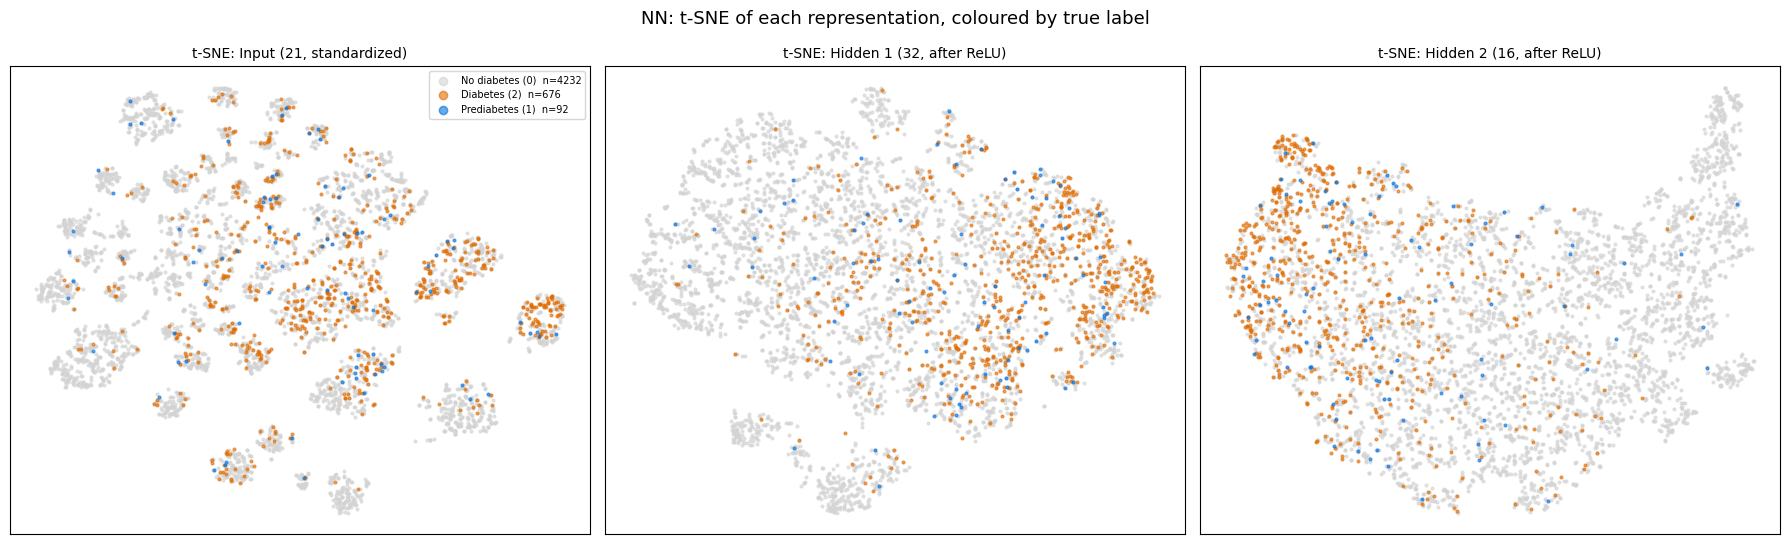

In [9]:
fig, axes = plt.subplots(1, len(reps), figsize=(6 * len(reps), 5.5))
for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), reps)):
    scatter_by_label(ax, tsne_embs[name], title=f't-SNE: {name}', legend=(i == 0))
fig.suptitle(f'{MODEL_TAG}: t-SNE of each representation, coloured by true label', fontsize=13)
plt.tight_layout()
plt.show()

## 4. Exercise 1: t-SNE vs PCA
PCA is a linear projection onto the two directions with the most variance. t-SNE is non-linear and only tries to keep the local neighbourhoods.

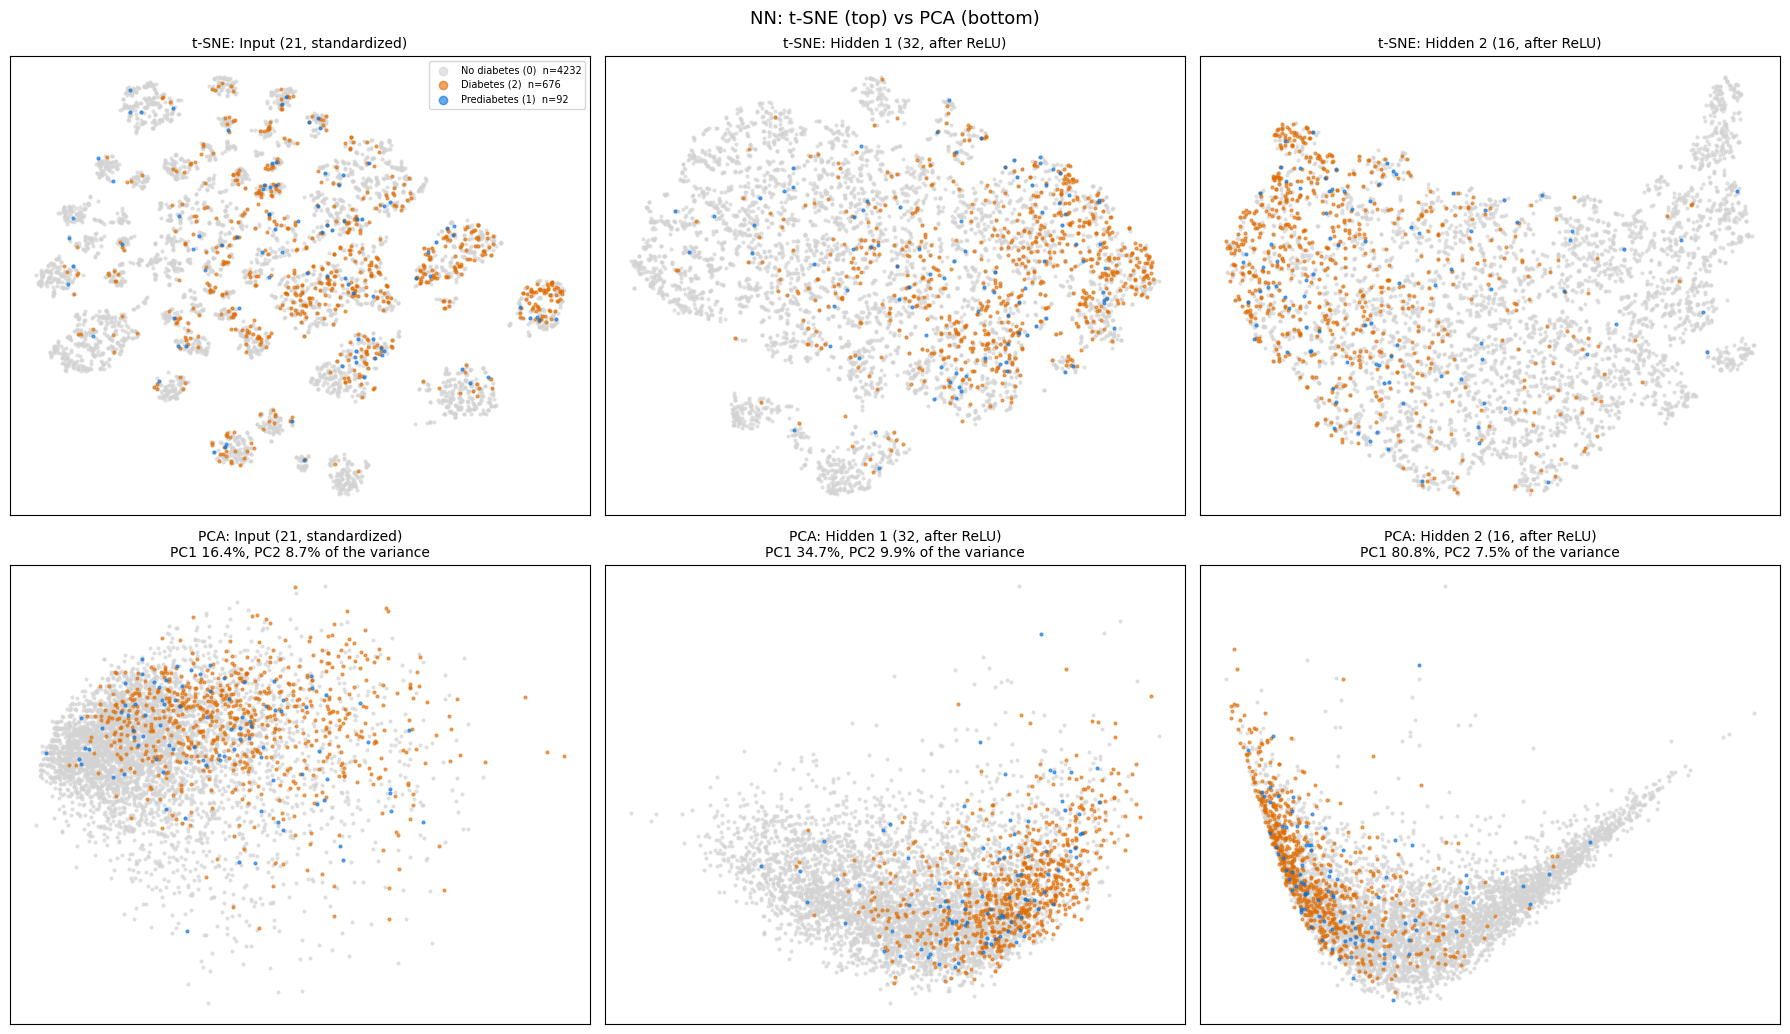

In [10]:
fig, axes = plt.subplots(2, len(reps), figsize=(6 * len(reps), 10.5))
for i, name in enumerate(reps):
    scatter_by_label(axes[0, i], tsne_embs[name], title=f't-SNE: {name}', legend=(i == 0))
    scatter_by_label(axes[1, i], pca_embs[name], legend=False,
                     title=f'PCA: {name}\nPC1 {100*pca_vars[name][0]:.1f}%, PC2 {100*pca_vars[name][1]:.1f}% of the variance')
fig.suptitle(f'{MODEL_TAG}: t-SNE (top) vs PCA (bottom)', fontsize=13)
plt.tight_layout()
plt.show()

## 5. Exercise 3: the perplexity hyperparameter
Perplexity is roughly the number of neighbours each point "cares about".
- **Low perplexity**: very local, which tends to break the data into many small (often fake) clusters.
- **High perplexity**: more global structure, but small groups can disappear.

Week 9 used `perplexity=3`. We use 30 as default.

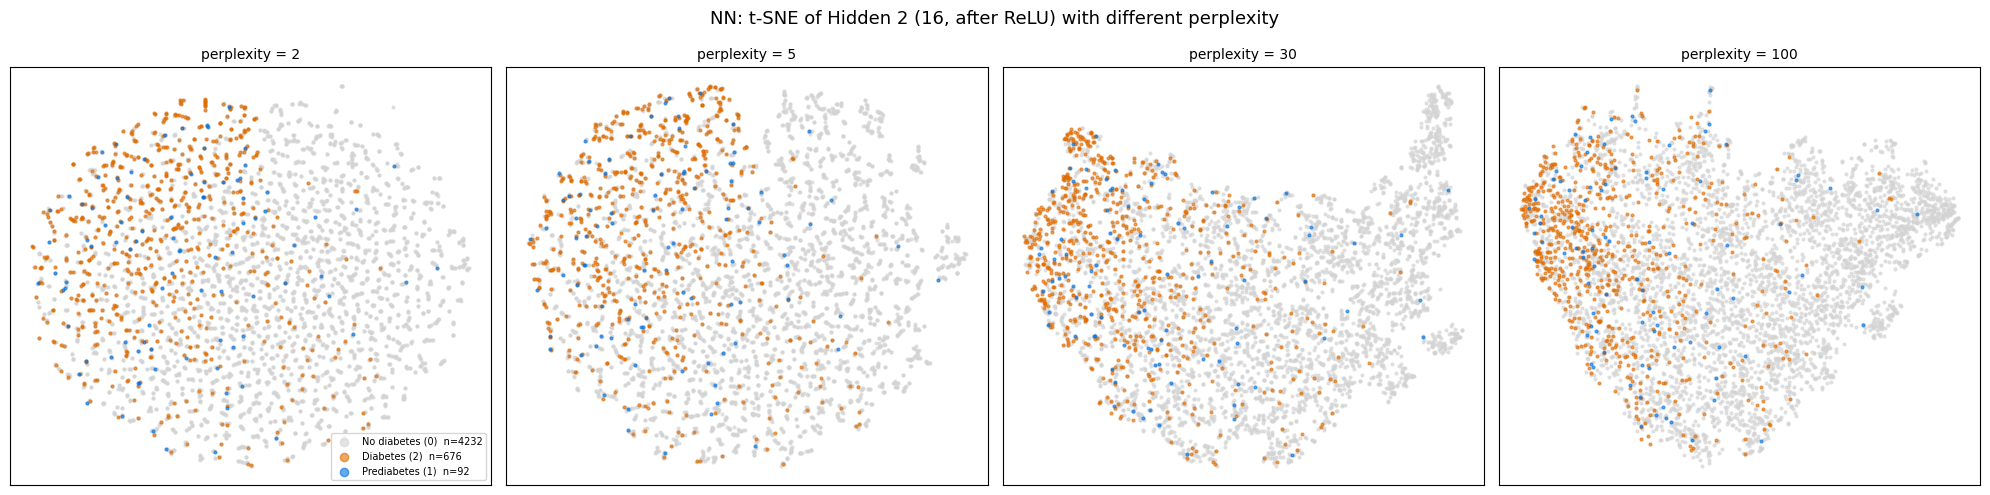

In [11]:
perplexities = [2, 5, 30, 100]
R = reps[MAIN_REP]

fig, axes = plt.subplots(1, len(perplexities), figsize=(5 * len(perplexities), 5))
for i, (ax, perp) in enumerate(zip(axes, perplexities)):
    emb = TSNE(**{**TSNE_KW, 'perplexity': perp}).fit_transform(R)
    scatter_by_label(ax, emb, title=f'perplexity = {perp}', legend=(i == 0))
fig.suptitle(f'{MODEL_TAG}: t-SNE of {MAIN_REP} with different perplexity', fontsize=13)
plt.tight_layout()
plt.show()

### 5.1 Can t-SNE make clusters that are not real?
We run t-SNE on pure Gaussian noise with the same shape as the hidden layer. Any cluster we see here is created by t-SNE itself.

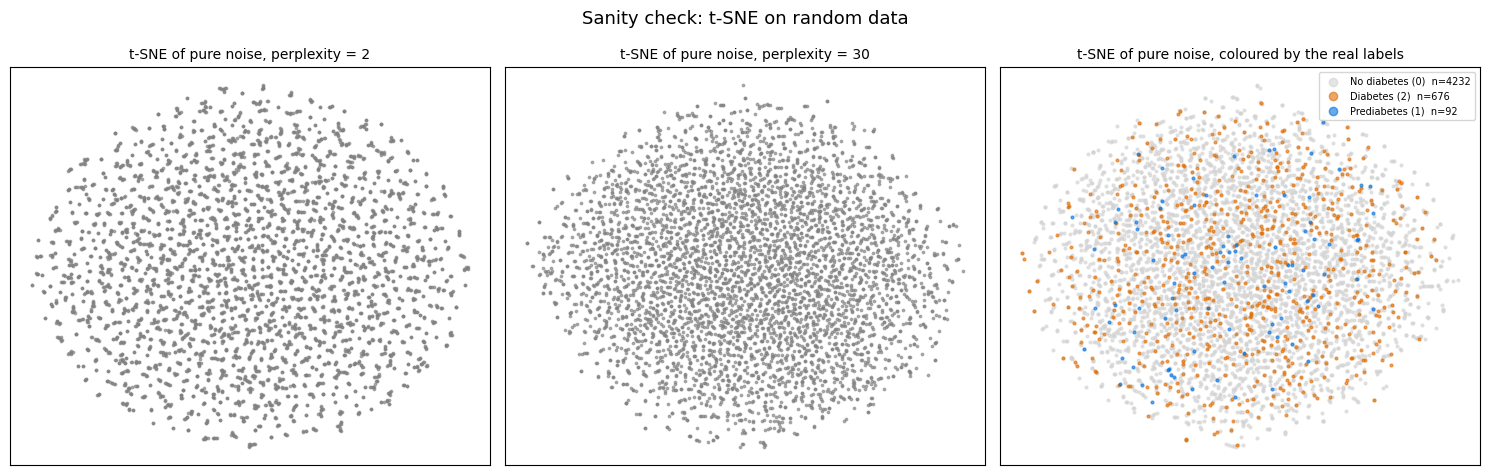

In [12]:
# Can t-SNE produce clusters that are not real?
# Gaussian noise with the same shape as our representation has NO cluster structure at all.
rng_noise = np.random.default_rng(SEED)
noise = rng_noise.standard_normal(reps[MAIN_REP].shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, perp in zip(axes, [2, 30]):
    emb = TSNE(**{**TSNE_KW, 'perplexity': perp, 'init': 'random'}).fit_transform(noise)
    ax.scatter(emb[:, 0], emb[:, 1], s=3, alpha=0.6, color='gray')
    ax.set_title(f't-SNE of pure noise, perplexity = {perp}', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

# Same noise, but with the real labels -> any "class separation" would be pure chance
emb = TSNE(**TSNE_KW).fit_transform(noise)
scatter_by_label(axes[2], emb, title='t-SNE of pure noise, coloured by the real labels', legend=True)
fig.suptitle('Sanity check: t-SNE on random data', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Exercise 4: UMAP
UMAP is like t-SNE built on a neighbour graph, but it usually keeps more of the global structure (the distances between groups mean a bit more) and is faster.

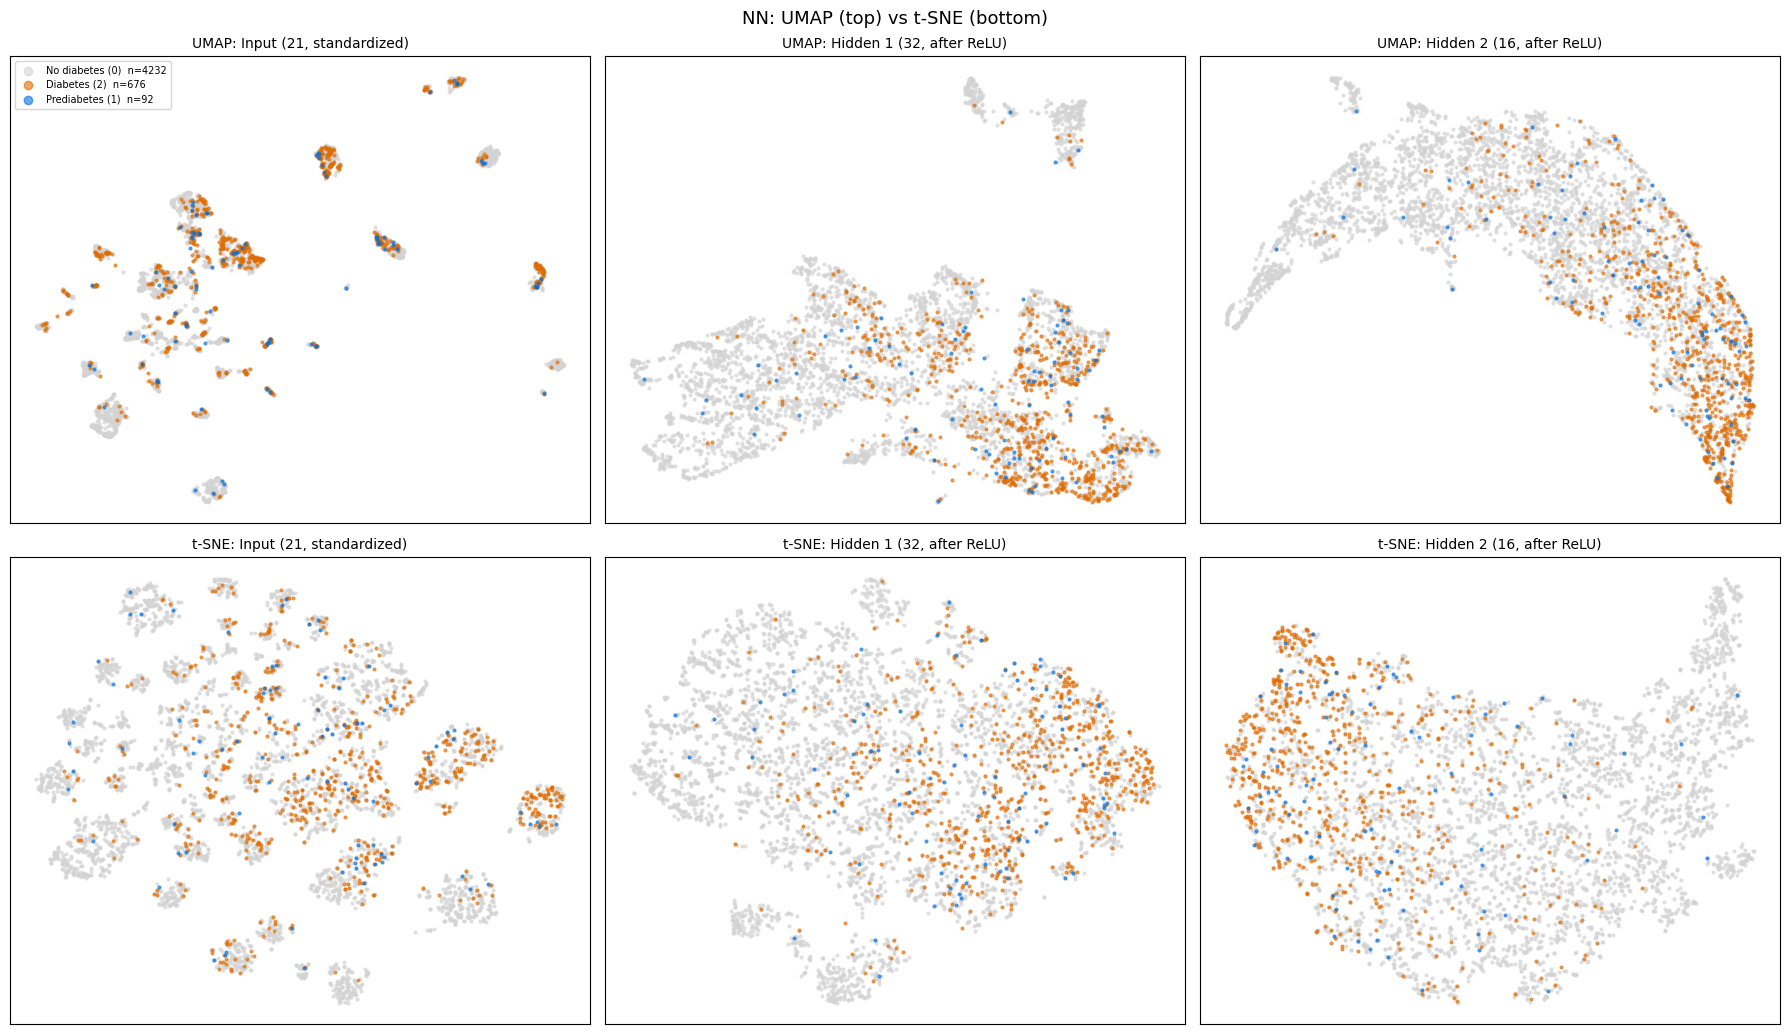

In [13]:
fig, axes = plt.subplots(2, len(reps), figsize=(6 * len(reps), 10.5))
for i, name in enumerate(reps):
    scatter_by_label(axes[0, i], umap_embs[name], title=f'UMAP: {name}', legend=(i == 0))
    scatter_by_label(axes[1, i], tsne_embs[name], title=f't-SNE: {name}', legend=False)
fig.suptitle(f'{MODEL_TAG}: UMAP (top) vs t-SNE (bottom)', fontsize=13)
plt.tight_layout()
plt.show()

### 6.1 UMAP hyperparameters
- `n_neighbors`: like perplexity. Small = local structure, large = global structure.
- `min_dist`: how tightly points may be packed. Small = dense clumps, large = more evenly spread.

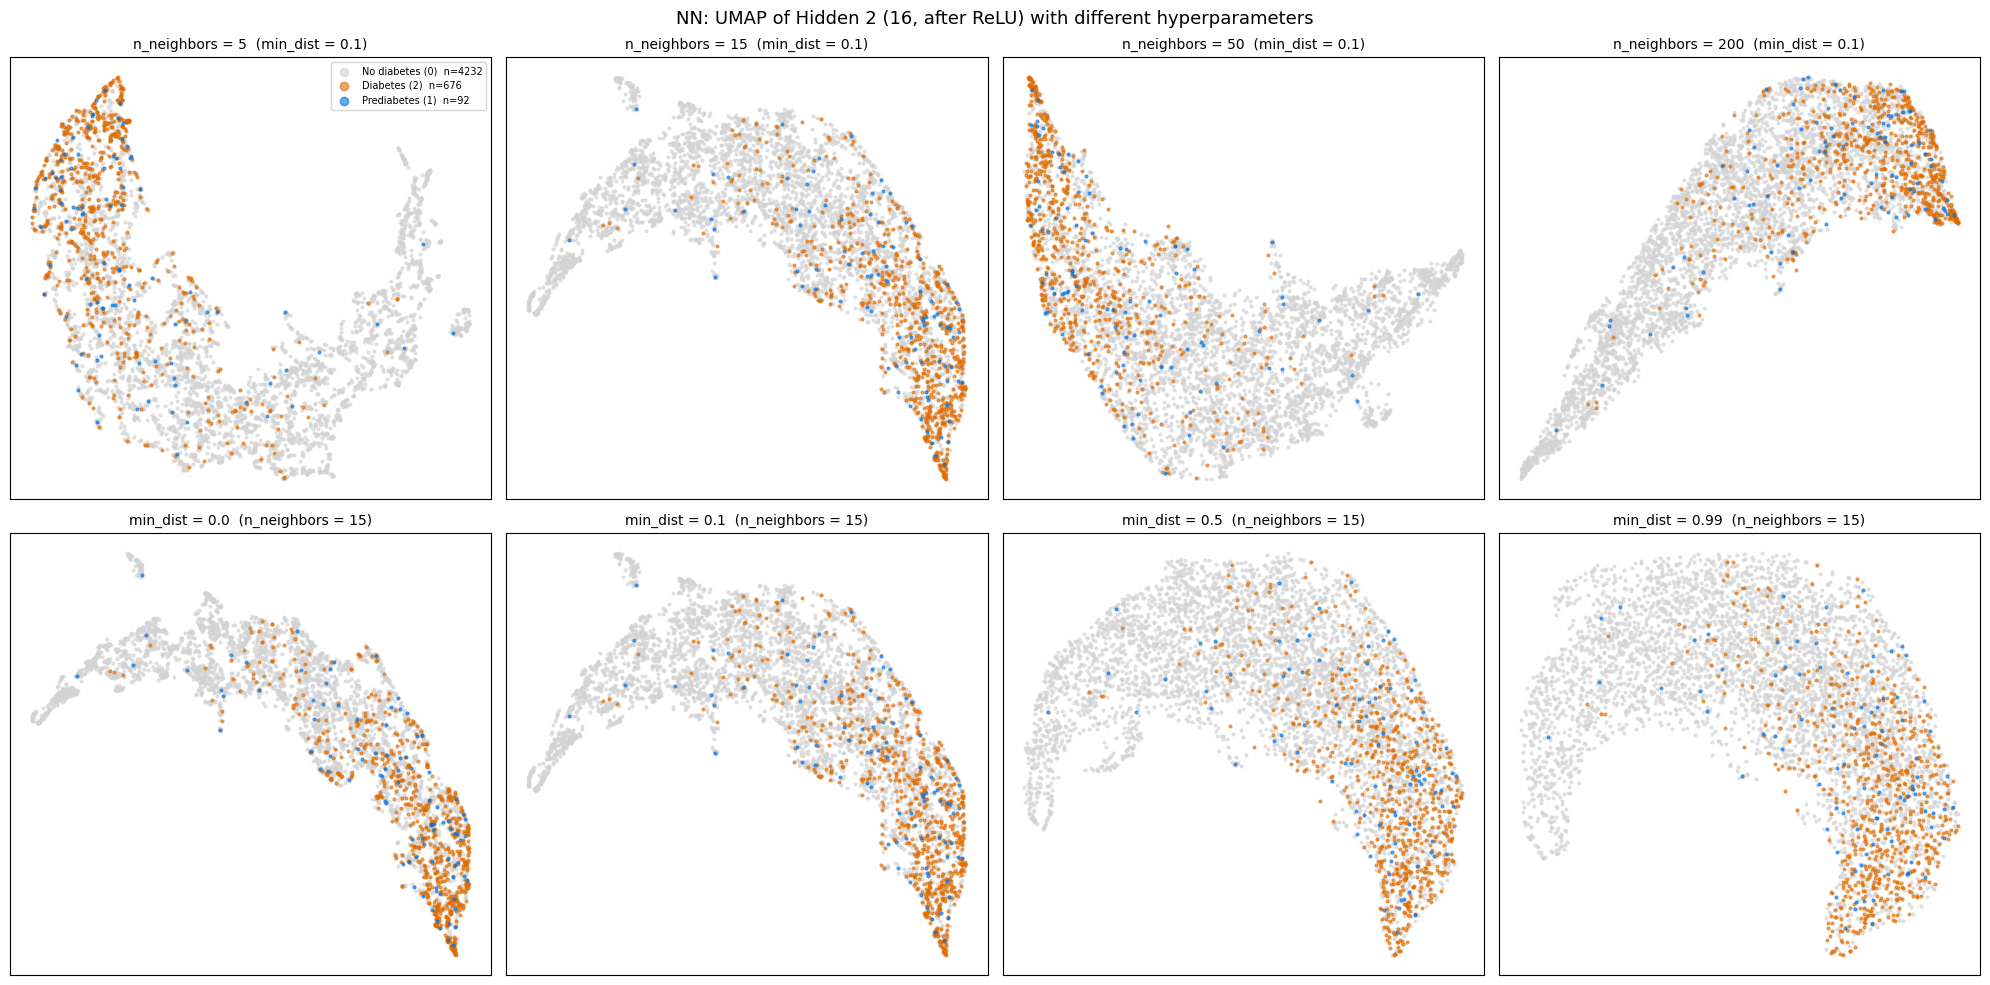

In [14]:
R = reps[MAIN_REP]
n_neighbors_list = [5, 15, 50, 200]
min_dist_list = [0.0, 0.1, 0.5, 0.99]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i, nn_ in enumerate(n_neighbors_list):
    emb = umap.UMAP(**{**UMAP_KW, 'n_neighbors': nn_}).fit_transform(R)
    scatter_by_label(axes[0, i], emb, title=f'n_neighbors = {nn_}  (min_dist = 0.1)', legend=(i == 0))
for i, md_ in enumerate(min_dist_list):
    emb = umap.UMAP(**{**UMAP_KW, 'min_dist': md_}).fit_transform(R)
    scatter_by_label(axes[1, i], emb, title=f'min_dist = {md_}  (n_neighbors = 15)', legend=False)
fig.suptitle(f'{MODEL_TAG}: UMAP of {MAIN_REP} with different hyperparameters', fontsize=13)
plt.tight_layout()
plt.show()

## 7. What does the network encode?
### 7.1 Coloured by the model's prediction
The true label is noisy (many persons with diabetes look "healthy" on the features). Colouring by the model's own output shows how the network organizes its representation.

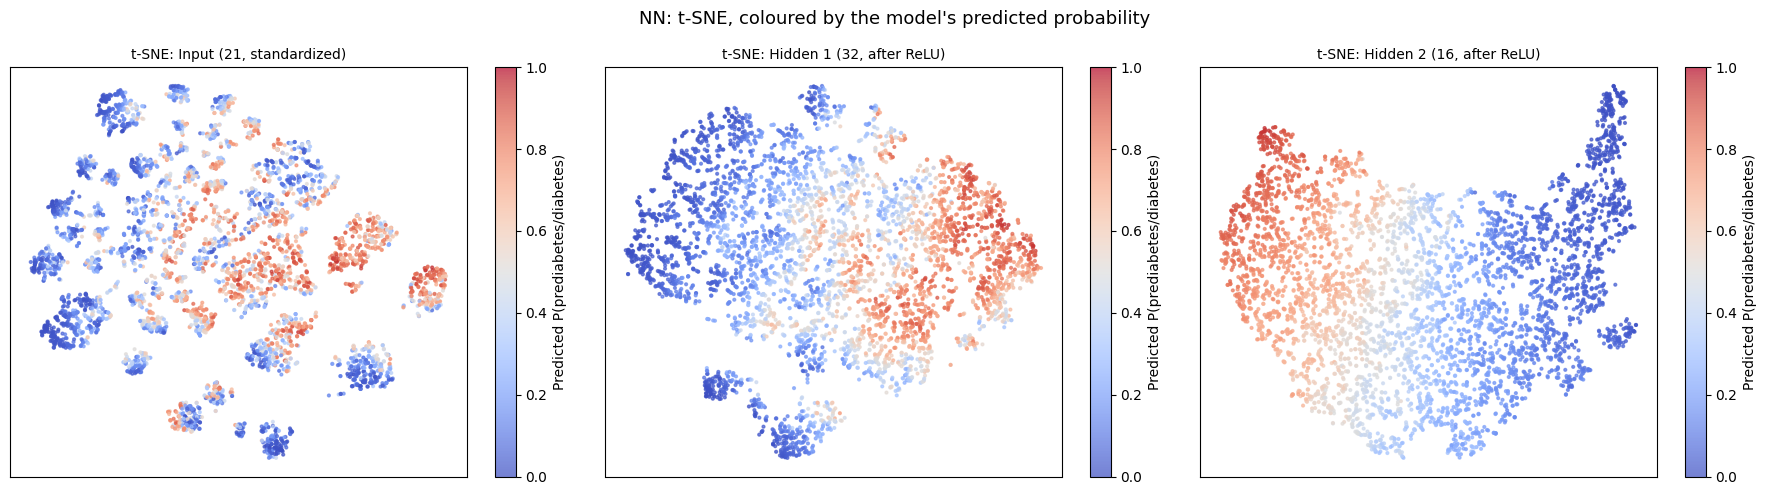

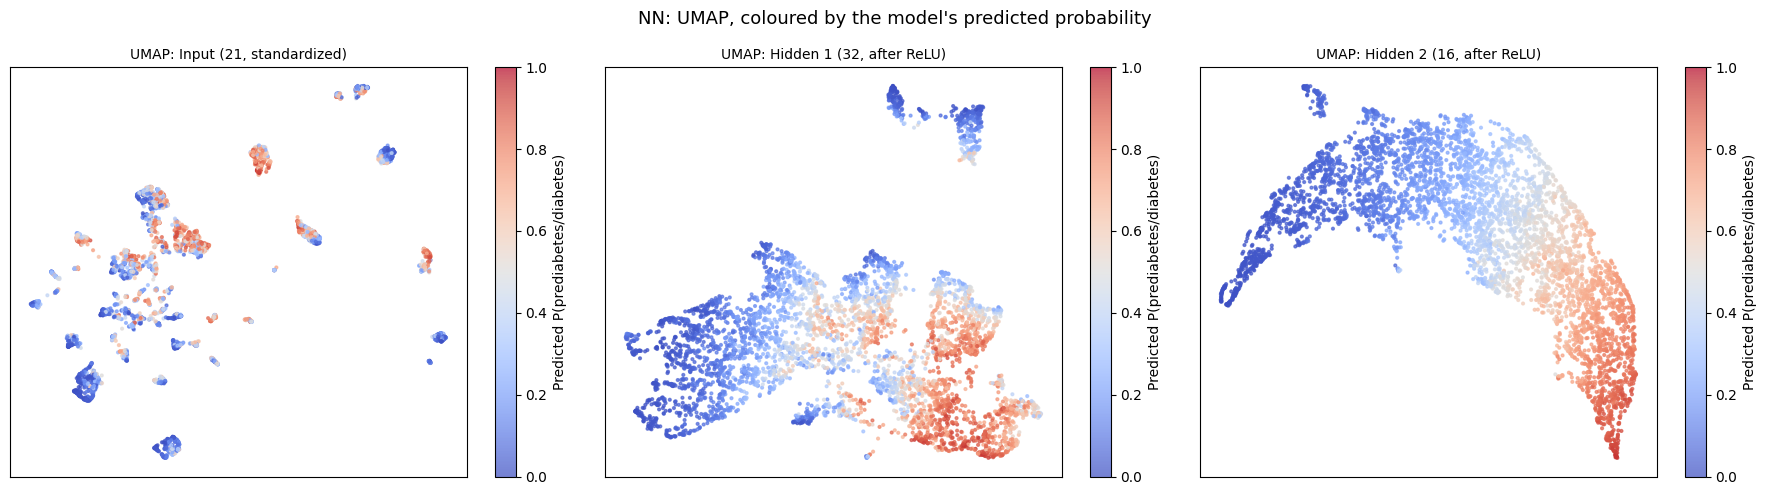

In [15]:
for method, embs in [('t-SNE', tsne_embs), ('UMAP', umap_embs)]:
    fig, axes = plt.subplots(1, len(reps), figsize=(6 * len(reps), 5))
    for ax, name in zip(np.atleast_1d(axes), reps):
        scatter_by_value(ax, embs[name], lat_proba, title=f'{method}: {name}', cmap='coolwarm',
                         vmin=0, vmax=1, label='Predicted P(prediabetes/diabetes)')
    fig.suptitle(f'{MODEL_TAG}: {method}, coloured by the model\'s predicted probability', fontsize=13)
    plt.tight_layout()
    plt.show()

### 7.2 Coloured by input features (concepts)
Which features does the last hidden layer organize itself around? A smooth colour gradient across the map means the layer encodes that feature strongly. This also connects to the TCAV analysis of *Income* in the main notebook.

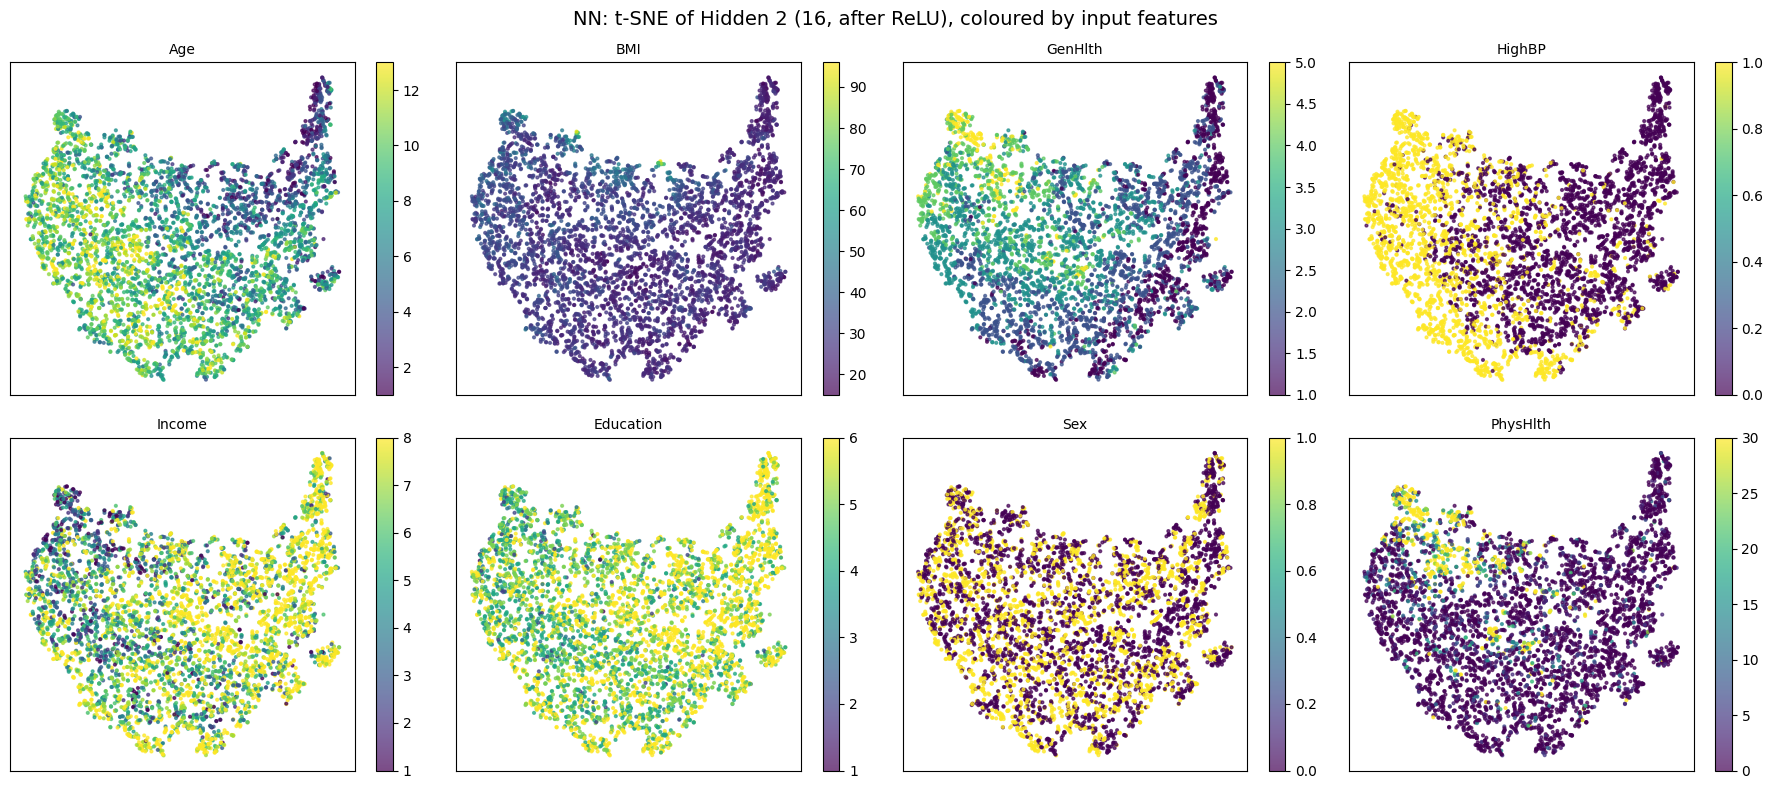

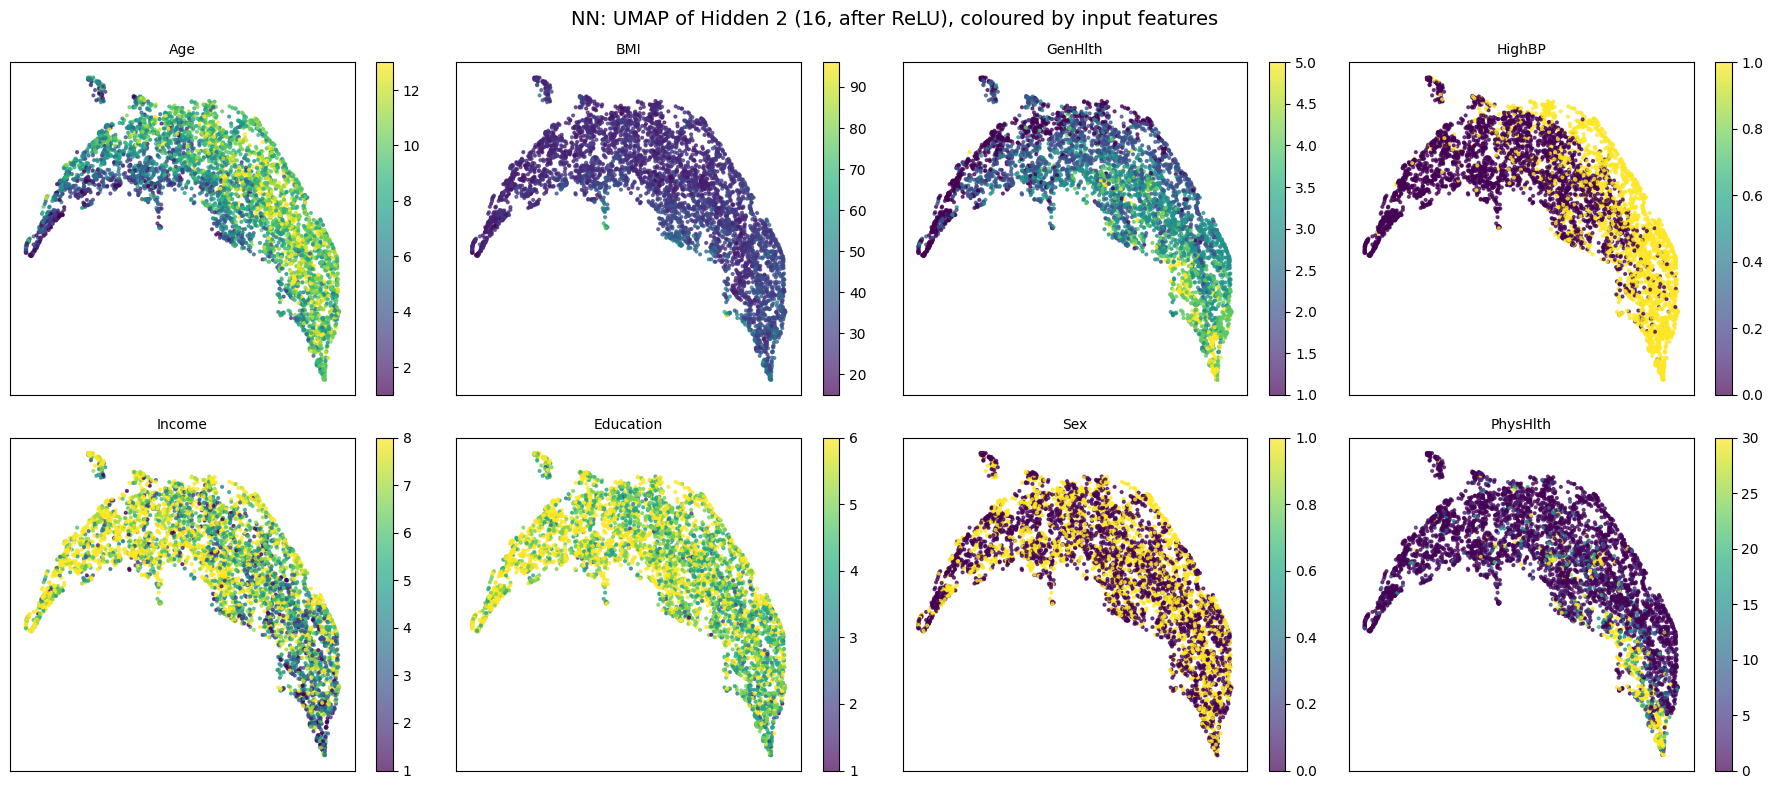

In [16]:
concept_features = ['Age', 'BMI', 'GenHlth', 'HighBP', 'Income', 'Education', 'Sex', 'PhysHlth']

for method, embs in [('t-SNE', tsne_embs), ('UMAP', umap_embs)]:
    emb = embs[MAIN_REP]
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, feat in zip(axes.ravel(), concept_features):
        scatter_by_value(ax, emb, lat_raw[:, FEATURE_COLS.index(feat)], title=feat)
    fig.suptitle(f'{MODEL_TAG}: {method} of {MAIN_REP}, coloured by input features', fontsize=14)
    plt.tight_layout()
    plt.show()

## 8. How much do the 2-D maps preserve? (quantitative check)
The plots are easy to over-interpret, so we add two numbers per map:

- **Trustworthiness** (0–1): are the neighbours of a person in the 2-D map also neighbours in the original space? 1 = the map invents no false neighbours.
- **k-NN balanced accuracy** (binary label, k = 15, 5-fold CV): if we predict a person's label from their neighbours, how well does it work? This measures how well the label is *locally* separated. 0.5 = random.

The "original" rows are the reference: what the full representation contains before it is squeezed into 2-D.

In [17]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict


def knn_bal_acc(Z, labels, k=15):
    """Balanced accuracy of a k-NN classifier (5-fold CV): how well do neighbours share the label?"""
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance')
    pred = cross_val_predict(knn, Z, labels, cv=5)
    return balanced_accuracy_score(labels, pred)


rows = []
for name, R in reps.items():
    rows.append({'representation': name, 'space': f'original ({R.shape[1]}-D)',
                 'trustworthiness (k=10)': 1.0, 'kNN balanced acc': knn_bal_acc(R, lat_y)})
    for method, embs in [('PCA', pca_embs), ('t-SNE', tsne_embs), ('UMAP', umap_embs)]:
        Z = embs[name]
        rows.append({'representation': name, 'space': f'{method} (2-D)',
                     'trustworthiness (k=10)': trustworthiness(R, Z, n_neighbors=10),
                     'kNN balanced acc': knn_bal_acc(Z, lat_y)})

quant_df = pd.DataFrame(rows)
print(f'Model balanced accuracy on the same {N_LATENT} persons: '
      f'{balanced_accuracy_score(lat_y, (lat_proba >= 0.5).astype(int)):.3f}\n')
print(quant_df.round(3).to_string(index=False))

Model balanced accuracy on the same 5000 persons: 0.754

           representation           space  trustworthiness (k=10)  kNN balanced acc
 Input (21, standardized) original (21-D)                   1.000             0.545
 Input (21, standardized)       PCA (2-D)                   0.715             0.557
 Input (21, standardized)     t-SNE (2-D)                   0.992             0.554
 Input (21, standardized)      UMAP (2-D)                   0.977             0.549
Hidden 1 (32, after ReLU) original (32-D)                   1.000             0.567
Hidden 1 (32, after ReLU)       PCA (2-D)                   0.841             0.585
Hidden 1 (32, after ReLU)     t-SNE (2-D)                   0.985             0.578
Hidden 1 (32, after ReLU)      UMAP (2-D)                   0.954             0.565
Hidden 2 (16, after ReLU) original (16-D)                   1.000             0.573
Hidden 2 (16, after ReLU)       PCA (2-D)                   0.942             0.585
Hidden 2 (16, after

## 9. What to look for
- Do the classes separate more from **input → hidden 1 → hidden 2**? (compare plots and the k-NN column)
- Is the separation visible in **PCA**, or only in t-SNE/UMAP? If only in t-SNE/UMAP, be careful: those methods can exaggerate clusters (Section 5.1).
- Is the structure **stable** across perplexity / `n_neighbors`? Structure that only appears for one setting should not be interpreted.
- Which **features** create the main gradients in the last hidden layer, and is Income among them?
- Compare with `Project2_LogReg_latent_tSNE_UMAP.ipynb`: the NN can bend the space, logistic regression cannot.